# Feature Engineering

In this step, we prepare the NASA C-MAPSS FD001 dataset for machine learning by creating the Remaining Useful Life (RUL) target variable and preparing relevant features for model training.

In [2]:
# IMPORT LIBARARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
columns = [
    "unit", "cycle",
    "setting_1", "setting_2", "setting_3",
    "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
    "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
    "sensor_21"
]

df = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None)
df.columns = columns
df.shape

(20631, 26)

In [4]:
df.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
# Identify constant columns
constant_columns = [
    col for col in df.columns
    if df[col].nunique() <= 1
]
print("Constant columns:", constant_columns)
print("Number of constant columns:", len(constant_columns))

Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Number of constant columns: 7


In [6]:
# to delete the constant coloumn

constant_cols = ["setting_3", "sensor_1", "sensor_5", "sensor_10",
                 "sensor_16", "sensor_18", "sensor_19"]

df = df.drop(columns=constant_cols)
df.shape

(20631, 19)

In [7]:
# Check the number of unique values in every column
df.nunique()

unit          100
cycle         362
setting_1     158
setting_2      13
sensor_2      310
sensor_3     3012
sensor_4     4051
sensor_6        2
sensor_7      513
sensor_8       53
sensor_9     6403
sensor_11     159
sensor_12     427
sensor_13      56
sensor_14    6078
sensor_15    1918
sensor_17      13
sensor_20     120
sensor_21    4745
dtype: int64

In [8]:
df["sensor_6"].value_counts()

sensor_6
21.61    20225
21.60      406
Name: count, dtype: int64

In [9]:
df["sensor_6"].nunique()

2

In [10]:
# TO create rul 
df["RUL"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]

df[df["unit"] == 1][["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


In [11]:
df["RUL"].describe()

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

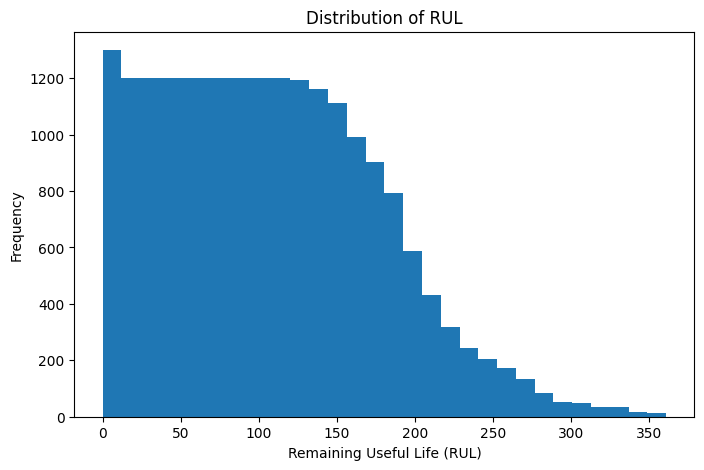

In [19]:
# To cheak the distribuation od the RUL
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["RUL"], bins=30)
plt.xlabel("Remaining Useful Life (RUL)")
plt.ylabel("Frequency")
plt.title("Distribution of RUL")
plt.show()

In [12]:
# Capping
df["RUL_clipped"] = df["RUL"].clip(upper=125)

df[["unit", "cycle", "RUL", "RUL_clipped"]].iloc[[0, 100, 191]]

,unit,cycle,RUL,RUL_clipped
0,1,1,191,125
100,1,101,91,91
191,1,192,0,0


In [13]:
# Train/Test validation
from sklearn.model_selection import train_test_split

# Get unique engine IDs
engine_ids = df["unit"].unique()

# Split engines into training and validation sets
train_units, val_units = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

# Create training and validation datasets
train_df = df[df["unit"].isin(train_units)].copy()
val_df = df[df["unit"].isin(val_units)].copy()

# Check the split
print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


In [14]:
# Scalling All The Training Data
from sklearn.preprocessing import StandardScaler

sensor_cols = [c for c in train_df.columns if c.startswith("sensor_")]

scaler = StandardScaler()
train_df[sensor_cols] = scaler.fit_transform(train_df[sensor_cols])
val_df[sensor_cols] = scaler.transform(val_df[sensor_cols])

print(len(sensor_cols), "sensors scaled")
print(train_df[sensor_cols].describe().T[["mean", "std"]].round(2).head())
print(val_df[sensor_cols].describe().T[["mean", "std"]].round(2).head())

15 sensors scaled
          mean  std
sensor_2  -0.0  1.0
sensor_3  -0.0  1.0
sensor_4  -0.0  1.0
sensor_6  -0.0  1.0
sensor_7  -0.0  1.0
          mean   std
sensor_2  0.03  1.02
sensor_3  0.03  1.04
sensor_4  0.03  1.02
sensor_6 -0.03  1.09
sensor_7 -0.03  1.04


In [15]:
# Rolling Feature 
import yaml

with open("../configs/config.yaml") as f:
    cfg = yaml.safe_load(f)

window = cfg["features"]["window_size"]

sensor_cols = [c for c in train_df.columns
               if c.startswith("sensor_") and "_mean" not in c and "_std" not in c]

def add_rolling(data, cols, window):
    data = data.sort_values(["unit", "cycle"]).copy()
    g = data.groupby("unit")[cols]

    roll_mean = g.transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    ).add_suffix(f"_mean{window}")

    roll_std = g.transform(
        lambda s: s.rolling(window, min_periods=2).std()
    ).fillna(0).add_suffix(f"_std{window}")

    return pd.concat([data, roll_mean, roll_std], axis=1)

train_df = add_rolling(train_df, sensor_cols, window)
val_df = add_rolling(val_df, sensor_cols, window)

print("window:", window, "| sensors:", len(sensor_cols))
print(train_df.shape, val_df.shape)
print("NaN:", train_df.isna().sum().sum(), val_df.isna().sum().sum())

window: 30 | sensors: 15
(16561, 51) (4070, 51)
NaN: 0 0


In [23]:
# Create a X and y feature 
feature_cols = (sensor_cols
                + [f"{c}_mean{window}" for c in sensor_cols]
                + [f"{c}_std{window}" for c in sensor_cols])

X_train, y_train = train_df[feature_cols], train_df["RUL_clipped"]
X_val, y_val = val_df[feature_cols], val_df["RUL_clipped"]

print("features:", len(feature_cols))
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)

features: 45
(16561, 45) (16561,)
(4070, 45) (4070,)


In [24]:
from pathlib import Path

Path("../data/processed").mkdir(parents=True, exist_ok=True)
Path("../models").mkdir(parents=True, exist_ok=True)

In [ ]:
# Save into the Processed Folder
import json
import joblib

train_df.to_csv("../data/processed/train_FD001_processed.csv", index=False)
val_df.to_csv("../data/processed/val_FD001_processed.csv", index=False)

joblib.dump(scaler, "../models/scaler.joblib")

with open("../data/processed/feature_cols.json", "w") as f:
    json.dump(feature_cols, f)

print("saved train:", train_df.shape, "| val:", val_df.shape)
print("saved features:", len(feature_cols))

saved train: (16561, 51) | val: (4070, 51)
saved features: 45


In [26]:

test_df = pd.read_csv("../data/raw/test_FD001.txt", sep=r"\s+", header=None)
test_df.columns = columns
test_df = test_df.drop(columns=constant_cols)

rul_true = pd.read_csv("../data/raw/RUL_FD001.txt", header=None)[0]

test_df[sensor_cols] = scaler.transform(test_df[sensor_cols])
test_df = add_rolling(test_df, sensor_cols, window)

test_last = test_df.groupby("unit").tail(1).set_index("unit")

X_test = test_last[feature_cols]
y_test = pd.Series(rul_true.values, index=test_last.index)

print(test_df.shape, X_test.shape, y_test.shape)
print("NaN:", X_test.isna().sum().sum())

(13096, 49) (100, 45) (100,)
NaN: 0


In [28]:

from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

X_test.to_csv(processed_dir / "X_test_FD001.csv", index=False)
y_test.to_csv(processed_dir / "y_test_FD001.csv", index=False)

print("X_test saved:", (processed_dir / "X_test_FD001.csv").exists())
print("y_test saved:", (processed_dir / "y_test_FD001.csv").exists())


X_test saved: True
y_test saved: True
